In [ ]:
!pip install -q google-adk vertexai requests

## ReadyNow! FEMA Emergency Response Agent — System Architecture

### Architectural Overview
1. **Deployment & Runtime Layer (`Vertex AI Agent Engine`)**:
   - Wraps the multi-agent hierarchy inside an `AdkApp` (`enable_tracing=True`) or `InMemoryRunner` for local testing.
   - Uses `gemini-2.5-flash` via the `global` Vertex AI endpoint with automatic `HttpRetryOptions`.
2. **Guardrails & Observability (`Callbacks`)**:
   - **`before_model_callback` (`chained_before_callback`)**: Intercepts incoming requests across all agents to run input moderation (`validate_user_input`) and audit logging (`log_user_prompt`).
   - **`after_model_callback` (`log_model_response`)**: Logs outgoing model responses for auditability.
3. **Orchestration Layer (`readynow_root_coordinator`)**:
   - Acts as the central entry point and router for user queries.
   - Uses **`AgentTool`** to invoke `severe_alerts_search_agent` (preventing conflicts between built-in `google_search` and ADK's `transfer_to_agent` tool).
   - Uses **ADK Sub-Agent Delegation (`transfer_to_agent`)** to hand off tasks to `weather_forecast_agent` and `evacuation_routing_agent`.
4. **Tools & External APIs**:
   - **OpenStreetMap Nominatim API**: Geocodes US city names into latitude/longitude (`get_lat_lon`).
   - **U.S. National Weather Service (NWS) API**: Fetches 5-period extended forecasts (`get_extended_weather_forecast`).
   - **Google Search Grounding**: Searches live emergency news and severe weather alerts (`google_search`).
   - **Evacuation Routing Logic**: Generates hazard-specific evacuation advisories (`get_safe_evacuation_routes`).

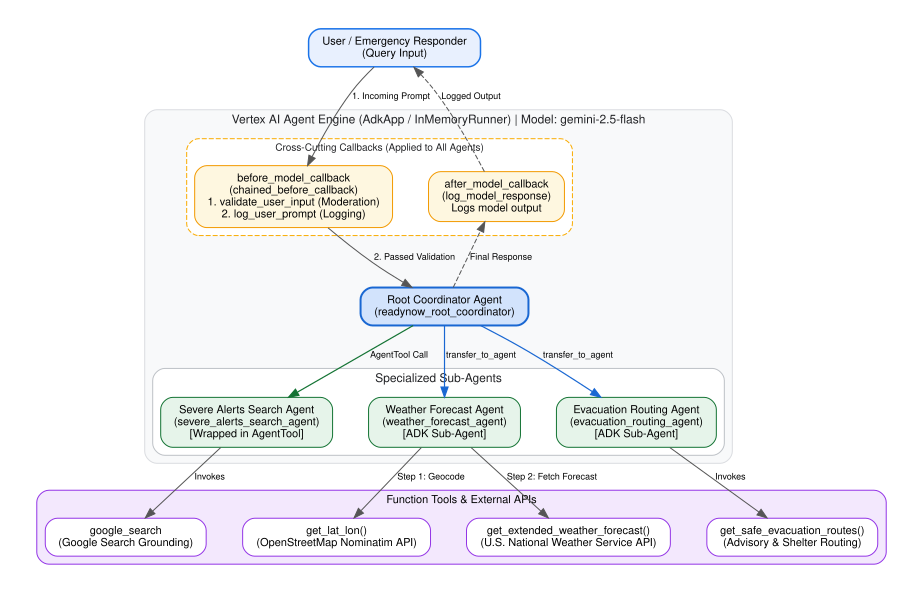

In [11]:
import graphviz
from IPython.display import display

dot = graphviz.Digraph(
    name="ReadyNow_FEMA_Architecture",
    comment="ReadyNow! FEMA Agent Architecture",
    format="png"
)
dot.attr(rankdir="TB", pad="0.4", nodesep="0.5", ranksep="0.7", fontname="Helvetica", bgcolor="white")
dot.attr("node", fontname="Helvetica", fontsize="11", style="rounded,filled", shape="box", margin="0.2,0.1")
dot.attr("edge", fontname="Helvetica", fontsize="9", color="#555555")

# 1. User Node
dot.node("user", "User / Emergency Responder\n(Query Input)", fillcolor="#E8F0FE", color="#1A73E8", penwidth="1.5")

# 2. Vertex AI Agent Engine Cluster
with dot.subgraph(name="cluster_runtime") as c:
    c.attr(label="Vertex AI Agent Engine (AdkApp / InMemoryRunner) | Model: gemini-2.5-flash", style="rounded,filled", fillcolor="#F8F9FA", color="#DADCE0", fontsize="12", fontcolor="#202124")

    # Guardrail & Logging Callbacks
    with c.subgraph(name="cluster_callbacks") as cb:
        cb.attr(label="Cross-Cutting Callbacks (Applied to All Agents)", style="rounded,dashed", fillcolor="#FFF8E1", color="#F9AB00", fontsize="10")
        cb.node("before_cb", "before_model_callback\n(chained_before_callback)\n1. validate_user_input (Moderation)\n2. log_user_prompt (Logging)", fillcolor="#FEF7E0", color="#F29900")
        cb.node("after_cb", "after_model_callback\n(log_model_response)\nLogs model output", fillcolor="#FEF7E0", color="#F29900")

    # Root Coordinator
    c.node("root", "Root Coordinator Agent\n(readynow_root_coordinator)", fillcolor="#D2E3FC", color="#1967D2", penwidth="2.0")

    # Sub-Agents & AgentTools
    with c.subgraph(name="cluster_agents") as ag:
        ag.attr(label="Specialized Sub-Agents", style="rounded", color="#BDC1C6", bgcolor="#FFFFFF")
        ag.node("search_agent", "Severe Alerts Search Agent\n(severe_alerts_search_agent)\n[Wrapped in AgentTool]", fillcolor="#E6F4EA", color="#137333")
        ag.node("weather_agent", "Weather Forecast Agent\n(weather_forecast_agent)\n[ADK Sub-Agent]", fillcolor="#E6F4EA", color="#137333")
        ag.node("evac_agent", "Evacuation Routing Agent\n(evacuation_routing_agent)\n[ADK Sub-Agent]", fillcolor="#E6F4EA", color="#137333")

# 3. Tools & External Services Cluster
with dot.subgraph(name="cluster_tools") as t:
    t.attr(label="Function Tools & External APIs", style="rounded,filled", fillcolor="#F3E8FD", color="#9334E6", fontsize="11")
    t.node("gsearch", "google_search\n(Google Search Grounding)", fillcolor="#FFFFFF", color="#9334E6")
    t.node("latlon", "get_lat_lon()\n(OpenStreetMap Nominatim API)", fillcolor="#FFFFFF", color="#9334E6")
    t.node("nws", "get_extended_weather_forecast()\n(U.S. National Weather Service API)", fillcolor="#FFFFFF", color="#9334E6")
    t.node("evac_tool", "get_safe_evacuation_routes()\n(Advisory & Shelter Routing)", fillcolor="#FFFFFF", color="#9334E6")

# Edges / Flow
dot.edge("user", "before_cb", label="1. Incoming Prompt")
dot.edge("before_cb", "root", label="2. Passed Validation")
dot.edge("root", "after_cb", label="Final Response", style="dashed")
dot.edge("after_cb", "user", label="Logged Output", style="dashed")

# Coordinator to Sub-Agents
dot.edge("root", "search_agent", label="AgentTool Call", color="#137333", penwidth="1.2")
dot.edge("root", "weather_agent", label="transfer_to_agent", color="#1967D2", penwidth="1.2")
dot.edge("root", "evac_agent", label="transfer_to_agent", color="#1967D2", penwidth="1.2")

# Sub-Agents to Tools
dot.edge("search_agent", "gsearch", label="Invokes")
dot.edge("weather_agent", "latlon", label="Step 1: Geocode")
dot.edge("weather_agent", "nws", label="Step 2: Fetch Forecast")
dot.edge("evac_agent", "evac_tool", label="Invokes")

display(dot)

In [ ]:
import logging
from typing import Optional, Dict, Any, List
import requests

from google.adk.agents import Agent, SequentialAgent
from google.adk.agents.callback_context import CallbackContext
from google.adk.models import LlmRequest, LlmResponse
from google.adk.tools import google_search
from vertexai.preview import reasoning_engines

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] [%(name)s]: %(message)s")
logger = logging.getLogger("ReadyNowFEMA")
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
def get_extended_weather_forecast(lat: float, lon: float) -> Optional[List[Dict[str, str]]]:
    """
    Fetch the extended weather forecast from the U.S. National Weather Service API
    based on a given latitude and longitude.

    Args:
        lat (float): Latitude of the location (e.g., 38.8977).
        lon (float): Longitude of the location (e.g., -77.0369).

    Returns:
        Optional[List[Dict[str, str]]]: A list of forecast periods, or None if failed.
    """
    try:
        points_url = f"https://api.weather.gov/points/{lat},{lon}"
        headers = {"User-Agent": "(readynow-fema-app, admin@fema.gov)"}
        res = requests.get(points_url, headers=headers, timeout=10)
        if res.status_code != 200:
            return None

        forecast_url = res.json().get("properties", {}).get("forecast")
        if not forecast_url:
            return None

        forecast_res = requests.get(forecast_url, headers=headers, timeout=10)
        if forecast_res.status_code != 200:
            return None

        periods = forecast_res.json().get("properties", {}).get("periods", [])
        return [
            {
                "name": p.get("name"),
                "temperature": f"{p.get('temperature')} {p.get('temperatureUnit')}",
                "forecast": p.get("detailedForecast")
            }
            for p in periods[:5]
        ]
    except Exception:
        logger.exception("Weather API fetch error")
        return None

def get_lat_lon(location_name: str) -> Dict[str, float]:
    """
    Convert a US city/location name into latitude and longitude coordinates.

    Args:
        location_name (str): Name of the US city or place.

    Returns:
        Dict[str, float]: Dictionary containing 'lat' and 'lon'.
    """
    try:
        url = f"https://nominatim.openstreetmap.org/search?q={location_name},+USA&format=json&limit=1"
        res = requests.get(url, headers={"User-Agent": "ReadyNowFEMAApp"}, timeout=10)
        data = res.json()
        if data:
            return {"lat": float(data[0]["lat"]), "lon": float(data[0]["lon"])}
    except Exception:
        pass
    return {"lat": 35.4676, "lon": -97.5164}  # Default fallback (Oklahoma City)

def get_safe_evacuation_routes(origin: str, disaster_type: str) -> str:
    """
    Provides suggested safe evacuation routes and shelter directions away from disaster zones.

    Args:
        origin (str): Starting location or affected city.
        disaster_type (str): Type of disaster (e.g., flash flood, wildfire, tornado).

    Returns:
        str: Evacuation advisory and routing guidance.
    """
    return (
        f"Evacuation Advisory for {origin} due to {disaster_type}: "
        "Proceed north/higher ground immediately away from low-lying areas. "
        "Monitor state emergency broadcast channels, avoid flooded roadways, "
        "and follow local highway patrol routing signs."
    )

In [ ]:
def log_user_prompt(callback_context: CallbackContext, llm_request: LlmRequest) -> Optional[LlmResponse]:
    """Logs incoming user interactions."""
    if llm_request.contents:
        last = llm_request.contents[-1]
        if last.role == "user" and last.parts and last.parts[0].text:
            logger.info("[USER_PROMPT] Agent: %s | Message: %s", callback_context.agent_name, last.parts[0].text.strip())
    return None

def log_model_response(callback_context: CallbackContext, llm_response: LlmResponse) -> Optional[LlmResponse]:
    """Logs outgoing model responses."""
    if llm_response.content and llm_response.content.parts:
        txt = llm_response.content.parts[0].text
        if txt:
            logger.info("[MODEL_RESPONSE] Agent: %s | Response: %s", callback_context.agent_name, txt.strip())
    return None

def validate_user_input(callback_context: CallbackContext, llm_request: LlmRequest) -> Optional[LlmResponse]:
    """Validates user prompts to block malicious or out-of-scope requests."""
    if not llm_request.contents:
        return None
    last = llm_request.contents[-1]
    if last.role == "user" and last.parts and last.parts[0].text:
        text = last.parts[0].text.lower()
        prohibited = ["hack", "exploit", "bomb", "recipe for disaster", "stock market prediction"]
        if any(term in text for term in prohibited):
            logger.warning("[MODERATION_BLOCK] Blocked prohibited query: %s", text)
            return LlmResponse(content={
                "role": "model",
                "parts": [{
                    "text": "Request refused. The ReadyNow! Assistant is restricted solely to emergency alerts, weather monitoring, and safety routing."
                }]
            })
    return None

def chained_before_callback(callback_context: CallbackContext, llm_request: LlmRequest) -> Optional[LlmResponse]:
    """Chains moderation validation and logging before hitting the model."""
    validation = validate_user_input(callback_context, llm_request)
    if validation is not None:
        return validation
    return log_user_prompt(callback_context, llm_request)

In [ ]:
import os
import asyncio
from google.adk.models import Gemini
from google.adk.runners import InMemoryRunner
from google.adk.tools.agent_tool import AgentTool
from google.genai.types import Content, Part, HttpRetryOptions
from IPython.display import Markdown, display

# Ensure Google Cloud environment variables are configured for Vertex AI
# Using 'global' location helps avoid single-region 429 capacity exhaustion
os.environ["GOOGLE_CLOUD_PROJECT"] = "qwiklabs-gcp-02-75ff770f7744"
os.environ["GOOGLE_CLOUD_LOCATION"] = "global"
os.environ["GOOGLE_GENAI_USE_VERTEXAI"] = "1"

# Configure Gemini model with automatic retry on 429 RESOURCE_EXHAUSTED
MODEL = Gemini(
    model="gemini-2.5-flash",
    retry_options=HttpRetryOptions(initial_delay=2, attempts=5)
)

# Define the sub-agents and root_coordinator
weather_agent = Agent(
    name="weather_forecast_agent",
    model=MODEL,
    description="Provides weather forecasts and coordinates for US locations.",
    instruction="Use get_lat_lon to find coordinates for a city, then use get_extended_weather_forecast to get the forecast.",
    tools=[get_lat_lon, get_extended_weather_forecast],
    before_model_callback=chained_before_callback,
    after_model_callback=log_model_response
)

search_alerts_agent = Agent(
    name="severe_alerts_search_agent",
    model=MODEL,
    description="Searches for active severe weather alerts and news using Google Search.",
    instruction="Search for active severe weather alerts or emergency advisories for the requested location.",
    tools=[google_search],
    before_model_callback=chained_before_callback,
    after_model_callback=log_model_response
)

evacuation_agent = Agent(
    name="evacuation_routing_agent",
    model=MODEL,
    description="Provides safe evacuation routes and shelter advice during emergencies.",
    instruction="Provide safe evacuation routes using get_safe_evacuation_routes when requested or when severe hazards are present.",
    tools=[get_safe_evacuation_routes],
    before_model_callback=chained_before_callback,
    after_model_callback=log_model_response
)

# Wrap search_alerts_agent in AgentTool so google_search is not mixed with ADK's transfer_to_agent tool
root_coordinator = Agent(
    name="readynow_root_coordinator",
    model=MODEL,
    description="ReadyNow! FEMA Emergency Response Coordinator.",
    instruction=(
        "You are the ReadyNow! FEMA Emergency Assistant. Coordinate with your sub-agents and tools to provide "
        "weather forecasts, active severe alerts, and evacuation guidance for users."
    ),
    tools=[AgentTool(agent=search_alerts_agent)],
    sub_agents=[weather_agent, evacuation_agent],
    before_model_callback=chained_before_callback,
    after_model_callback=log_model_response
)

# 1. Instantiate the ADK in-memory runner for your root coordinator
runner = InMemoryRunner(
    agent=root_coordinator,
    app_name="readynow_app"
)

# 2. Create a test session
async def run_local_test():
    session = await runner.session_service.create_session(
        app_name="readynow_app",
        user_id="fema-eval-tester"
    )
    print(f"Created Session ID: {session.id}\n")

    # 3. Format message using GenAI Content types
    content = Content(
        role="user",
        parts=[Part.from_text(text="What is the weather and are there any active severe alerts for Oklahoma City, OK?")]
    )

    print("Querying agent...")
    for event in runner.run(new_message=content, user_id="fema-eval-tester", session_id=session.id):
        if event.content and event.content.parts and event.content.parts[0].text:
            print(f"** {event.author}: {event.content.parts[0].text}")

# Execute the async test helper in Jupyter
await run_local_test()

Created Session ID: 3d41da7f-b42d-4b7b-927f-a9a92838a6bf

Querying agent...
** readynow_root_coordinator: As of Wednesday, October 14, 2026, at 9 PM UTC, Oklahoma City, Oklahoma, is under a Flood Watch until Thursday, October 15, 2026, at 1:00 PM CDT (6 PM UTC) due to the possibility of flooding caused by excessive rainfall. Earlier today, a Flash Flood Warning was in effect until 1:00 PM CDT. The forecast includes heavy rain and showers.


** weather_forecast_agent: The weather forecast for Oklahoma City, Oklahoma is as follows:

*   **This Afternoon (Wednesday):** Showers and thunderstorms. Mostly cloudy, with a high near 79°F. East wind around 7 mph. There is a 90% chance of precipitation, with new rainfall amounts between a quarter and half of an inch possible.
*   **Tonight (Wednesday Night):** Showers and thunderstorms. Mostly cloudy, with a low around 68°F. Southeast wind 7 to 10 mph. There is a 100% chance of precipitation, with new rainfall amounts between 1 and 2 inches possi

In [ ]:
import logging
from typing import Optional
from google.adk.agents.callback_context import CallbackContext
from google.adk.models import LlmRequest, LlmResponse
from google.genai.types import Content, Part

logger = logging.getLogger("ReadyNowFEMA")

# 1. Fix validate_user_input in the notebook session to use proper Content/Part objects
def validate_user_input(callback_context: CallbackContext, llm_request: LlmRequest) -> Optional[LlmResponse]:
    """Validates user prompts to block malicious or out-of-scope requests."""
    if not llm_request.contents:
        return None
    last = llm_request.contents[-1]
    if last.role == "user" and last.parts and last.parts[0].text:
        text = last.parts[0].text.lower()
        prohibited = ["hack", "exploit", "bomb", "recipe for disaster", "stock market prediction"]
        if any(term in text for term in prohibited):
            logger.warning("[MODERATION_BLOCK] Blocked prohibited query: %s", text)
            return LlmResponse(
                content=Content(
                    role="model",
                    parts=[Part.from_text(text="Request refused. The ReadyNow! Assistant is restricted solely to emergency alerts, weather monitoring, and safety routing.")]
                )
            )
    return None

# Update the callback reference on existing agents if they exist in memory
if "weather_agent" in globals():
    for ag in [weather_agent, search_alerts_agent, evacuation_agent, root_coordinator]:
        ag.before_model_callback = chained_before_callback

# 2. Ensure staging bucket exists
PROJECT_ID = "qwiklabs-gcp-02-75ff770f7744"
LOCATION = "us-central1"
STAGING_BUCKET = f"gs://{PROJECT_ID}-agent-staging"
!gsutil mb -p {PROJECT_ID} -l {LOCATION} {STAGING_BUCKET} 2>/dev/null || true
print(f"Staging bucket ready: {STAGING_BUCKET}")


Staging bucket ready: gs://qwiklabs-gcp-02-75ff770f7744-agent-staging


In [ ]:
from pathlib import Path

deploy_script = '''import os
import logging
from typing import Optional, Dict, List
import requests

import vertexai
from vertexai import agent_engines
from vertexai.preview.reasoning_engines import AdkApp
from google.adk.agents import Agent
from google.adk.agents.callback_context import CallbackContext
from google.adk.models import LlmRequest, LlmResponse, Gemini
from google.adk.tools import google_search
from google.adk.tools.agent_tool import AgentTool
from google.genai.types import Content, Part, HttpRetryOptions

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] [%(name)s]: %(message)s")
logger = logging.getLogger("ReadyNowFEMA")

# Ensure global endpoint is used for Gemini calls to avoid regional 429s
os.environ["GOOGLE_CLOUD_PROJECT"] = "qwiklabs-gcp-02-75ff770f7744"
os.environ["GOOGLE_CLOUD_LOCATION"] = "global"
os.environ["GOOGLE_GENAI_USE_VERTEXAI"] = "1"

def get_extended_weather_forecast(lat: float, lon: float) -> Optional[List[Dict[str, str]]]:
    """Fetch the extended weather forecast from the U.S. National Weather Service API."""
    try:
        points_url = f"https://api.weather.gov/points/{lat},{lon}"
        headers = {"User-Agent": "(readynow-fema-app, admin@fema.gov)"}
        res = requests.get(points_url, headers=headers, timeout=10)
        if res.status_code != 200:
            return None
        forecast_url = res.json().get("properties", {}).get("forecast")
        if not forecast_url:
            return None
        forecast_res = requests.get(forecast_url, headers=headers, timeout=10)
        if forecast_res.status_code != 200:
            return None
        periods = forecast_res.json().get("properties", {}).get("periods", [])
        return [
            {
                "name": p.get("name"),
                "temperature": f"{p.get('temperature')} {p.get('temperatureUnit')}",
                "forecast": p.get("detailedForecast")
            }
            for p in periods[:5]
        ]
    except Exception:
        logger.exception("Weather API fetch error")
        return None

def get_lat_lon(location_name: str) -> Dict[str, float]:
    """Convert a US city/location name into latitude and longitude coordinates."""
    try:
        url = f"https://nominatim.openstreetmap.org/search?q={location_name},+USA&format=json&limit=1"
        res = requests.get(url, headers={"User-Agent": "ReadyNowFEMAApp"}, timeout=10)
        data = res.json()
        if data:
            return {"lat": float(data[0]["lat"]), "lon": float(data[0]["lon"])}
    except Exception:
        pass
    return {"lat": 35.4676, "lon": -97.5164}

def get_safe_evacuation_routes(origin: str, disaster_type: str) -> str:
    """Provides suggested safe evacuation routes and shelter directions away from disaster zones."""
    return (
        f"Evacuation Advisory for {origin} due to {disaster_type}: "
        "Proceed north/higher ground immediately away from low-lying areas. "
        "Monitor state emergency broadcast channels, avoid flooded roadways, "
        "and follow local highway patrol routing signs."
    )

def log_user_prompt(callback_context: CallbackContext, llm_request: LlmRequest) -> Optional[LlmResponse]:
    if llm_request.contents:
        last = llm_request.contents[-1]
        if last.role == "user" and last.parts and last.parts[0].text:
            logger.info("[USER_PROMPT] Agent: %s | Message: %s", callback_context.agent_name, last.parts[0].text.strip())
    return None

def log_model_response(callback_context: CallbackContext, llm_response: LlmResponse) -> Optional[LlmResponse]:
    if llm_response.content and llm_response.content.parts:
        txt = llm_response.content.parts[0].text
        if txt:
            logger.info("[MODEL_RESPONSE] Agent: %s | Response: %s", callback_context.agent_name, txt.strip())
    return None

def validate_user_input(callback_context: CallbackContext, llm_request: LlmRequest) -> Optional[LlmResponse]:
    if not llm_request.contents:
        return None
    last = llm_request.contents[-1]
    if last.role == "user" and last.parts and last.parts[0].text:
        text = last.parts[0].text.lower()
        prohibited = ["hack", "exploit", "bomb", "recipe for disaster", "stock market prediction"]
        if any(term in text for term in prohibited):
            logger.warning("[MODERATION_BLOCK] Blocked prohibited query: %s", text)
            return LlmResponse(
                content=Content(
                    role="model",
                    parts=[Part.from_text(text="Request refused. The ReadyNow! Assistant is restricted solely to emergency alerts, weather monitoring, and safety routing.")]
                )
            )
    return None

def chained_before_callback(callback_context: CallbackContext, llm_request: LlmRequest) -> Optional[LlmResponse]:
    validation = validate_user_input(callback_context, llm_request)
    if validation is not None:
        return validation
    return log_user_prompt(callback_context, llm_request)

MODEL = Gemini(
    model="gemini-2.5-flash",
    retry_options=HttpRetryOptions(initial_delay=2, attempts=5)
)

weather_agent = Agent(
    name="weather_forecast_agent",
    model=MODEL,
    description="Provides weather forecasts and coordinates for US locations.",
    instruction="Use get_lat_lon to find coordinates for a city, then use get_extended_weather_forecast to get the forecast.",
    tools=[get_lat_lon, get_extended_weather_forecast],
    before_model_callback=chained_before_callback,
    after_model_callback=log_model_response
)

search_alerts_agent = Agent(
    name="severe_alerts_search_agent",
    model=MODEL,
    description="Searches for active severe weather alerts and news using Google Search.",
    instruction="Search for active severe weather alerts or emergency advisories for the requested location.",
    tools=[google_search],
    before_model_callback=chained_before_callback,
    after_model_callback=log_model_response
)

evacuation_agent = Agent(
    name="evacuation_routing_agent",
    model=MODEL,
    description="Provides safe evacuation routes and shelter advice during emergencies.",
    instruction="Provide safe evacuation routes using get_safe_evacuation_routes when requested or when severe hazards are present.",
    tools=[get_safe_evacuation_routes],
    before_model_callback=chained_before_callback,
    after_model_callback=log_model_response
)

root_coordinator = Agent(
    name="readynow_root_coordinator",
    model=MODEL,
    description="ReadyNow! FEMA Emergency Response Coordinator.",
    instruction=(
        "You are the ReadyNow! FEMA Emergency Assistant. Coordinate with your sub-agents and tools to provide "
        "weather forecasts, active severe alerts, and evacuation guidance for users."
    ),
    tools=[AgentTool(agent=search_alerts_agent)],
    sub_agents=[weather_agent, evacuation_agent],
    before_model_callback=chained_before_callback,
    after_model_callback=log_model_response
)

if __name__ == "__main__":
    PROJECT_ID = "qwiklabs-gcp-02-75ff770f7744"
    LOCATION = "us-central1"
    STAGING_BUCKET = f"gs://{PROJECT_ID}-agent-staging"

    vertexai.init(project=PROJECT_ID, location=LOCATION, staging_bucket=STAGING_BUCKET)

    adk_app = AdkApp(agent=root_coordinator, enable_tracing=True)

    print("1. Testing AdkApp locally via stream_query...")
    for event in adk_app.stream_query(
        user_id="playground-tester",
        message="What are the safe evacuation routes for Miami during a hurricane?"
    ):
        print(event)

    print("2. Deploying to Vertex AI Agent Engine...")
    remote_agent = agent_engines.create(
        adk_app,
        display_name="readynow-fema-agent",
        requirements=[
            "google-adk",
            "google-cloud-aiplatform[adk,agent_engines]>=1.88.0",
            "google-genai",
            "requests",
        ],
        env_vars={
            "GOOGLE_CLOUD_LOCATION": "global",
            "GOOGLE_GENAI_USE_VERTEXAI": "1",
        }
    )
    print(f"Successfully deployed! Resource Name: {remote_agent.resource_name}")
'''

Path("deploy_agent.py").write_text(deploy_script)
!python3 deploy_agent.py


/usr/local/lib/python3.12/dist-packages/google/cloud/aiplatform/models.py:52: FutureWarning: Support for google-cloud-storage < 3.0.0 will be removed in a future version of google-cloud-aiplatform. Please upgrade to google-cloud-storage >= 3.0.0.
  from google.cloud.aiplatform.utils import gcs_utils
1. Testing AdkApp locally via stream_query...
2026-10-14 22:01:11,186 [WARNING] [vertexai.preview.reasoning_engines.templates.adk]: telemetry enabled but proceeding without GenAI instrumentation, because not all packages (i.e. opentelemetry-instrumentation-google-genai) have been installed
/usr/local/lib/python3.12/dist-packages/vertexai/preview/reasoning_engines/templates/adk.py:1005: UserWarning: [EXPERIMENTAL] InMemoryCredentialService: This feature is experimental and may change or be removed in future versions without notice. It may introduce breaking changes at any time.
  self._tmpl_attrs["credential_service"] = InMemoryCredentialService()
/usr/local/lib/python3.12/dist-packages/goog